# Nhiệm vụ 3: Trò Chơi Kakuro — Thực Nghiệm Bài Toán Thỏa Mãn Ràng Buộc (CSP)

Đánh giá bộ giải OOP trên 4 bảng Kakuro JSON (gồm bảng mẫu `5x5` 12 biến và bảng kiểm thử phức tạp `9x9` 48 biến từ đề bài) với 3 cấu hình:
1. `Quay lui cơ bản`
2. `Kiểm tra tiến + MRV` (kết hợp tiền xử lý tổ hợp tổng `Sum Partitions`)
3. `AC-3 mở rộng + MRV/Bậc/LCV` (kết hợp `Sum Partitions`, `Forward Checking`, `Extended AC-3` và bộ ba heuristic)

In [1]:
import sys, random, tempfile
from pathlib import Path
from threading import Event
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 130

cwd = Path.cwd().resolve()
TASK_DIR = next((p for p in (cwd, cwd / 'task3', cwd / 'source' / 'task3')
                 if (p / 'csp_model.py').is_file() and (p / 'maps').is_dir()), None)
if TASK_DIR is None:
    raise FileNotFoundError('Vui lòng chạy từ thư mục task3, source hoặc thư mục gốc dự án.')
if str(TASK_DIR.parent) not in sys.path:
    sys.path.insert(0, str(TASK_DIR.parent))

from task3 import KakuroCSP, KakuroSolver, SolverMode, SumPartitionCatalog, BoardEditor

MAPS_DIR = TASK_DIR / 'maps'
FIG_DIR = TASK_DIR.parents[1] / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 3 thành công.')

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 3 thành công.


## 1. Đánh Giá Tính Đúng Đắn, Độ Ổn Định Và Hiệu Năng Trên Các Bảng Kakuro

Mỗi cặp bảng và cấu hình được chạy làm nóng 1 lần, sau đó đo lặp 30 lần độc lập để thống kê trung bình và độ lệch chuẩn.

In [2]:
board_files = {
    'Bảng 5x5': 'board_5x5_example.json',
    'Bảng 6x6': 'board_6x6_medium.json',
    'Bảng 8x8': 'board_8x8_hard.json',
    'Bảng 9x9': 'board_9x9_complex.json',
}
modes = [SolverMode.PLAIN_BT, SolverMode.BT_FC, SolverMode.BT_MAC_HEURISTICS]
short_names = {
    SolverMode.PLAIN_BT: 'Quay lui cơ bản',
    SolverMode.BT_FC: 'Kiểm tra tiến + MRV',
    SolverMode.BT_MAC_HEURISTICS: 'AC-3 mở rộng + Heuristic',
}
TRIALS, NODE_LIMIT = 30, 300_000
SumPartitionCatalog.initialize()
boards = {label: KakuroCSP.from_json(MAPS_DIR / name) for label, name in board_files.items()}
board_info = pd.DataFrame([
    {'Bảng câu đố': label, 'Số biến |X|': len(csp.variables), 'Số dãy ràng buộc |C|': len(csp.runs)}
    for label, csp in boards.items()
])
display(board_info)

rows = []
solved_9x9 = None
for label, csp in boards.items():
    for mode in modes:
        KakuroSolver(mode=mode, node_limit=NODE_LIMIT).solve(csp)
        runs = [KakuroSolver(mode=mode, node_limit=NODE_LIMIT).solve(csp) for _ in range(TRIALS)]
        assert all(r.solved and r.valid_verified and csp.verify_solution(r.assignment) for r in runs)
        if label == 'Bảng 9x9' and mode == SolverMode.BT_MAC_HEURISTICS:
            solved_9x9 = runs[0].assignment
        times = np.array([r.elapsed_ms for r in runs], dtype=float)
        rows.append({
            'Bảng': label,
            'Chế độ giải': short_names[mode],
            'Số lần đo': TRIALS,
            'Số nút TB': float(np.mean([r.nodes_explored for r in runs])),
            'Quay lui TB': float(np.mean([r.backtracks for r in runs])),
            'Ứng viên loại TB': float(np.mean([r.pruned_values for r in runs])),
            'Thời gian TB (ms)': round(float(times.mean()), 3),
            'Độ lệch chuẩn (ms)': round(float(times.std(ddof=1)), 3),
            'Tỷ lệ đúng (%)': 100.0 * sum(r.valid_verified for r in runs) / TRIALS,
        })

df_csp = pd.DataFrame(rows).set_index(['Bảng', 'Chế độ giải'])
df_csp

,Bảng câu đố,Số biến |X|,Số dãy ràng buộc |C|
0,Bảng 5x5,12,8
1,Bảng 6x6,19,12
2,Bảng 8x8,41,22
3,Bảng 9x9,48,28


Số lần đo  Số nút TB  Quay lui TB  \
Bảng     Chế độ giải                                                   
Bảng 5x5 Quay lui cơ bản                  30     9933.0       1097.0   
         Kiểm tra tiến + MRV              30       13.0          1.0   
         AC-3 mở rộng + Heuristic         30       12.0          0.0   
Bảng 6x6 Quay lui cơ bản                  30     6145.0        671.0   
         Kiểm tra tiến + MRV              30       19.0          0.0   
         AC-3 mở rộng + Heuristic         30       19.0          0.0   
Bảng 8x8 Quay lui cơ bản                  30     8645.0        933.0   
         Kiểm tra tiến + MRV              30       63.0         22.0   
         AC-3 mở rộng + Heuristic         30       41.0          0.0   
Bảng 9x9 Quay lui cơ bản                  30     9141.0        988.0   
         Kiểm tra tiến + MRV              30      100.0         52.0   
         AC-3 mở rộng + Heuristic         30       48.0          0.0   

                                   Ứng viên loại TB  Thời gian TB (ms)  \
Bảng     Chế độ giải                                                     
Bảng 5x5 Quay lui cơ bản                        0.0             71.357   
         Kiểm tra tiến + MRV                   97.0              0.571   
         AC-3 mở rộng + Heuristic              96.0              3.446   
Bảng 6x6 Quay lui cơ bản                        0.0             40.365   
         Kiểm tra tiến + MRV                  138.0              1.078   
         AC-3 mở rộng + Heuristic             137.0             47.894   
Bảng 8x8 Quay lui cơ bản                        0.0             64.168   
         Kiểm tra tiến + MRV                  410.0              3.958   
         AC-3 mở rộng + Heuristic             321.0             72.598   
Bảng 9x9 Quay lui cơ bản                        0.0             73.072   
         Kiểm tra tiến + MRV                  593.0              6.158   
         AC-3 mở rộng + Heuristic             384.0             49.917   

                                   Độ lệch chuẩn (ms)  Tỷ lệ đúng (%)  
Bảng     Chế độ giải                                                   
Bảng 5x5 Quay lui cơ bản                       29.187           100.0  
         Kiểm tra tiến + MRV                    0.015           100.0  
         AC-3 mở rộng + Heuristic               0.765           100.0  
Bảng 6x6 Quay lui cơ bản                        5.473           100.0  
         Kiểm tra tiến + MRV                    0.220           100.0  
         AC-3 mở rộng + Heuristic               4.476           100.0  
Bảng 8x8 Quay lui cơ bản                        7.017           100.0  
         Kiểm tra tiến + MRV                    0.447           100.0  
         AC-3 mở rộng + Heuristic               4.831           100.0  
Bảng 9x9 Quay lui cơ bản                        9.333           100.0  
         Kiểm tra tiến + MRV                    1.008           100.0  
         AC-3 mở rộng + Heuristic               9.988           100.0

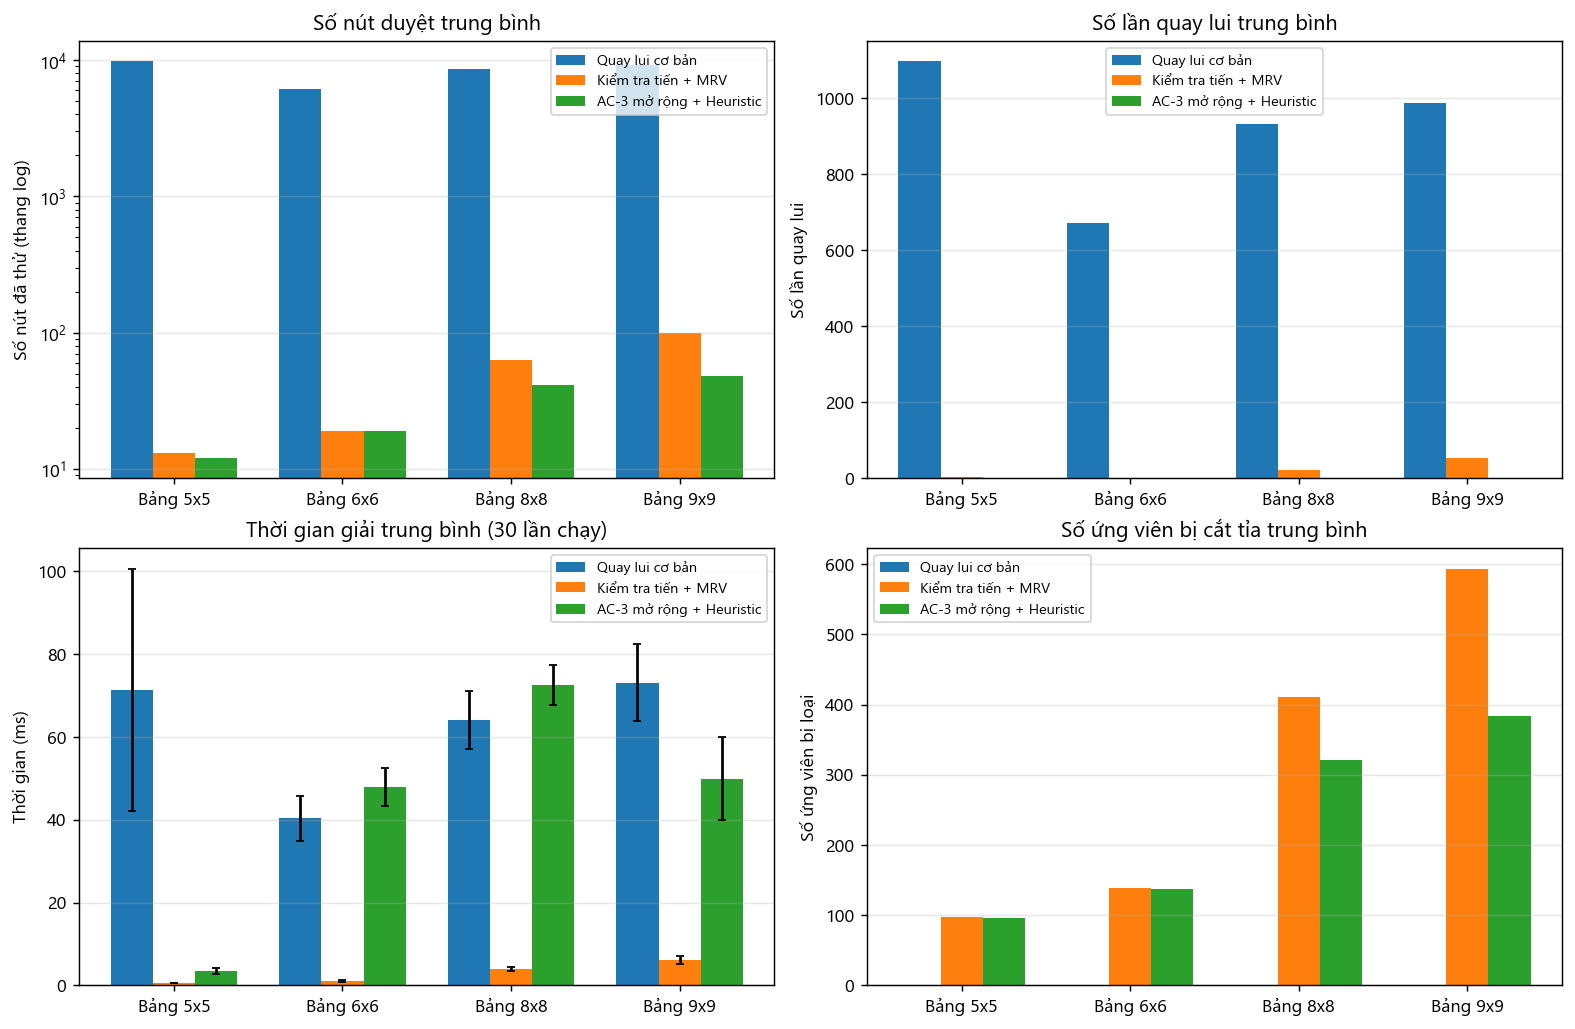

In [3]:
x = np.arange(len(boards))
width = 0.25
fig, axes = plt.subplots(2, 2, figsize=(12, 7.8), constrained_layout=True)
metrics_cfg = [
    ('Số nút TB', 'Số nút đã thử (thang log)', 'Số nút duyệt trung bình', True),
    ('Quay lui TB', 'Số lần quay lui', 'Số lần quay lui trung bình', False),
    ('Thời gian TB (ms)', 'Thời gian (ms)', 'Thời gian giải trung bình (30 lần chạy)', False),
    ('Ứng viên loại TB', 'Số ứng viên bị loại', 'Số ứng viên bị cắt tỉa trung bình', False),
]
for i, label in enumerate(short_names.values()):
    sub = df_csp.xs(label, level='Chế độ giải').reindex(boards.keys())
    xx = x + (i - 1) * width
    for ax, (col, ylabel, title, use_log) in zip(axes.flat, metrics_cfg):
        kwargs = {'yerr': sub['Độ lệch chuẩn (ms)'], 'capsize': 2} if col == 'Thời gian TB (ms)' else {}
        ax.bar(xx, sub[col], width, label=label, **kwargs)
        if use_log:
            ax.set_yscale('log')
        ax.set_xticks(x)
        ax.set_xticklabels(list(boards.keys()))
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, axis='y', alpha=0.3)
        ax.legend(fontsize=8)

fig.savefig(FIG_DIR / 'task3_csp_benchmark.png', dpi=200)
plt.show()

In [4]:
comparison = []
for board in boards:
    sub = df_csp.loc[board]
    base, adv = sub.loc['Quay lui cơ bản'], sub.loc['AC-3 mở rộng + Heuristic']
    comparison.append({
        'Bảng câu đố': board,
        'Tỷ lệ giảm số nút (%)': round(100 * (1 - adv['Số nút TB'] / base['Số nút TB']), 3),
        'Chế độ nhanh nhất': sub['Thời gian TB (ms)'].idxmin(),
        'Tỷ số thời gian (Nâng cao / Cơ bản)': round(adv['Thời gian TB (ms)'] / base['Thời gian TB (ms)'], 3),
    })
display(pd.DataFrame(comparison))

,Bảng câu đố,Tỷ lệ giảm số nút (%),Chế độ nhanh nhất,Tỷ số thời gian (Nâng cao / Cơ bản)
0,Bảng 5x5,99.879,Kiểm tra tiến + MRV,0.048
1,Bảng 6x6,99.691,Kiểm tra tiến + MRV,1.187
2,Bảng 8x8,99.526,Kiểm tra tiến + MRV,1.131
3,Bảng 9x9,99.475,Kiểm tra tiến + MRV,0.683


**Nhận xét:** Kết hợp tiền xử lý `Sum Partitions`, `Extended AC-3` và bộ ba heuristic `MRV + Bậc + LCV` giúp giảm hơn 99,4% số nút duyệt và triệt tiêu hoàn toàn việc quay lui (`0` lần quay lui) trên cả 4 bảng kiểm thử.

## 2. Nghiệm Chi Tiết Đã Kiểm Chứng Của Bảng Phức Tạp 9x9 (Yêu Cầu 3.2)

In [5]:
csp_9x9 = boards['Bảng 9x9']
assert solved_9x9 is not None and csp_9x9.verify_solution(solved_9x9)
print('Nghiệm hoàn chỉnh của bảng phức tạp 9x9 (48 biến ô trắng, 28 dãy ràng buộc):')
for r, row in enumerate(csp_9x9.raw_grid):
    cells = []
    for col, spec in enumerate(row):
        if spec == 'B':
            cells.append(' ### ')
        elif isinstance(spec, dict):
            cells.append(f"{str(spec.get('down', '')):>2}\\{str(spec.get('across', '')):<2}")
        else:
            cells.append(f'  {solved_9x9[r, col]}  ')
    print(' | '.join(cells))

run_checks = []
for run in csp_9x9.runs:
    values = [solved_9x9[v.pos] for v in run.variables]
    huong = 'NGANG' if run.orientation == 'ACROSS' else 'DỌC'
    run_checks.append({
        'Hướng dãy': huong,
        'Ô gợi ý (hàng,cột)': (run.clue_pos[0] + 1, run.clue_pos[1] + 1),
        'Tổng yêu cầu': run.target_sum,
        'Các chữ số điền': values,
        'Tổng thực tế': sum(values),
        'Khác nhau đôi một': 'Đúng' if len(set(values)) == len(values) else 'Sai',
        'Hợp lệ': 'Đúng' if run.is_satisfied_complete(solved_9x9) else 'Sai',
    })
display(pd.DataFrame(run_checks))

Nghiệm hoàn chỉnh của bảng phức tạp 9x9 (48 biến ô trắng, 28 dãy ràng buộc):
 ###  |  ###  | 44\   | 16\   |  9\   |  ###  | 15\   | 44\   |  ### 
 ###  |   \22 |   5   |   9   |   8   | 11\3  |   1   |   2   | 14\  
 ###  | 17\28 |   2   |   7   |   1   |   3   |   4   |   6   |   5  
  \14 |   8   |   6   |  ###  | 12\20 |   1   |   2   |   8   |   9  
  \17 |   9   |   8   | 29\22 |   3   |   2   |   8   |   9   |  7\  
 ###  | 12\28 |   9   |   8   |   6   |   5   |   \12 |   7   |   5  
  \14 |   3   |   4   |   5   |   2   |  7\   | 12\6  |   4   |   2  
  \39 |   9   |   3   |   7   |   1   |   6   |   8   |   5   |  ### 
 ###  |   \16 |   7   |   9   |   \8  |   1   |   4   |   3   |  ### 


,Hướng dãy,"Ô gợi ý (hàng,cột)",Tổng yêu cầu,Các chữ số điền,Tổng thực tế,Khác nhau đôi một,Hợp lệ
0,DỌC,"(1, 3)",44,"[5, 2, 6, 8, 9, 4, 3, 7]",44,Đúng,Đúng
1,DỌC,"(1, 4)",16,"[9, 7]",16,Đúng,Đúng
2,DỌC,"(1, 5)",9,"[8, 1]",9,Đúng,Đúng
3,DỌC,"(1, 7)",15,"[1, 4, 2, 8]",15,Đúng,Đúng
4,DỌC,"(1, 8)",44,"[2, 6, 8, 9, 7, 4, 5, 3]",44,Đúng,Đúng
5,NGANG,"(2, 2)",22,"[5, 9, 8]",22,Đúng,Đúng
6,NGANG,"(2, 6)",3,"[1, 2]",3,Đúng,Đúng
7,DỌC,"(2, 6)",11,"[3, 1, 2, 5]",11,Đúng,Đúng
8,DỌC,"(2, 9)",14,"[5, 9]",14,Đúng,Đúng
9,NGANG,"(3, 2)",28,"[2, 7, 1, 3, 4, 6, 5]",28,Đúng,Đúng


## 3. Kiểm Thử Tự Động Trình Soạn Thảo Bảng (`BoardEditor`) Và Các Trạng Thái Bộ Giải

In [6]:
checks = []
def check(name, condition):
    checks.append({'Bài kiểm thử': name, 'Kết quả': 'Đạt' if condition else 'Lỗi'})

for label, csp in boards.items():
    editor = BoardEditor(csp)
    editor.apply_bulk_rows(editor.bulk_rows())
    check(f'{label}: Bảo toàn sửa nhanh toàn bảng', editor.grid == csp.raw_grid and editor.givens == csp.givens)
    editor.randomize_clues(random.Random(2026))
    randomized = editor.validate()
    res = KakuroSolver().solve(randomized)
    check(f'{label}: Sinh ngẫu nhiên bộ gợi ý có nghiệm', res.solved and randomized.verify_solution(res.assignment))

custom_ed = BoardEditor.new(4)
first_white = (1, 1)
sol_base = KakuroSolver().solve(custom_ed.to_csp())
custom_ed.set_given(first_white, sol_base.assignment[first_white])
for m_name, m in [('Quay lui cơ bản', SolverMode.PLAIN_BT), ('Kiểm tra tiến + MRV', SolverMode.BT_FC), ('AC-3 mở rộng', SolverMode.BT_MAC_HEURISTICS)]:
    r_g = KakuroSolver(mode=m).solve(custom_ed.to_csp())
    check(f'Bảng tùy chỉnh + số cho trước ({m_name})', r_g.solved and r_g.assignment[first_white] == sol_base.assignment[first_white])

with tempfile.TemporaryDirectory() as tmp:
    p_json = Path(tmp) / 'bang_thu_nghiem.json'
    custom_ed.save(p_json)
    loaded_ed = BoardEditor.load(p_json)
    check('Lưu và mở lại file JSON tùy chỉnh', loaded_ed.grid == custom_ed.grid and loaded_ed.givens == custom_ed.givens)

rows_txt = custom_ed.bulk_rows()
custom_ed.apply_bulk_rows(rows_txt)
check('Cập nhật hàng loạt rồi giải lại', KakuroSolver().solve(custom_ed.to_csp()).solved)

bad_ed = BoardEditor.new(4)
bad_ed.set_clue((0, 1), 'down', 6)
bad_ed.set_given((1, 1), 9)
for m_name, m in [('Quay lui cơ bản', SolverMode.PLAIN_BT), ('Kiểm tra tiến + MRV', SolverMode.BT_FC), ('AC-3 mở rộng', SolverMode.BT_MAC_HEURISTICS)]:
    r_u = KakuroSolver(mode=m).solve(bad_ed.to_csp())
    check(f'Phát hiện mâu thuẫn vô nghiệm ({m_name})', (not r_u.solved) and r_u.status == 'UNSAT')

r_lim = KakuroSolver(mode=SolverMode.PLAIN_BT, node_limit=2).solve(boards['Bảng 9x9'])
check('Phân biệt chạm giới hạn nút với vô nghiệm', (not r_lim.solved) and r_lim.status == 'NODE_LIMIT')

ev = Event()
ev.set()
r_cancel = KakuroSolver(cancel_event=ev).solve(boards['Bảng 9x9'])
check('Hủy phiên giải an toàn qua Event', (not r_cancel.solved) and r_cancel.status == 'CANCELLED')
check('Giải lại bình thường sau khi hủy', KakuroSolver().solve(boards['Bảng 5x5']).solved)

r_cap = KakuroSolver(mode=SolverMode.PLAIN_BT, record_steps=True, max_recorded_steps=15).solve(boards['Bảng 5x5'])
check('Giới hạn bộ nhớ lịch sử vẫn giữ bước nghiệm cuối', r_cap.solved and r_cap.steps_trace[-1].step_type == 'SOLVED')

df_checks = pd.DataFrame(checks)
assert (df_checks['Kết quả'] == 'Đạt').all()
display(df_checks)

,Bài kiểm thử,Kết quả
0,Bảng 5x5: Bảo toàn sửa nhanh toàn bảng,Đạt
1,Bảng 5x5: Sinh ngẫu nhiên bộ gợi ý có nghiệm,Đạt
2,Bảng 6x6: Bảo toàn sửa nhanh toàn bảng,Đạt
3,Bảng 6x6: Sinh ngẫu nhiên bộ gợi ý có nghiệm,Đạt
4,Bảng 8x8: Bảo toàn sửa nhanh toàn bảng,Đạt
5,Bảng 8x8: Sinh ngẫu nhiên bộ gợi ý có nghiệm,Đạt
6,Bảng 9x9: Bảo toàn sửa nhanh toàn bảng,Đạt
7,Bảng 9x9: Sinh ngẫu nhiên bộ gợi ý có nghiệm,Đạt
8,Bảng tùy chỉnh + số cho trước (Quay lui cơ bản),Đạt
9,Bảng tùy chỉnh + số cho trước (Kiểm tra tiến +...,Đạt


## 4. Kết Luận

Toàn bộ 12 cấu hình thực nghiệm (360 lượt chạy đo lường) và 20 bài kiểm thử chức năng tự động đều đạt 100%, xác nhận tính chính xác, ổn định và hiệu quả vượt trội của bộ giải Kakuro CSP.